[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/06_nba.ipynb)

# 🏀 ¿A quién fichamos? Estadística descriptiva con los jugadores de la NBA (temporada 2021-22)

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

### 💼 El encargo
Sois el departamento de análisis de un equipo de la NBA. El director deportivo os pide:
- ¿Quiénes son los mejores **anotadores**? ¿Y los que más anotan **por minuto jugado**?
- ¿Hay **gangas**: jugadores que juegan pocos minutos pero rinden mucho cuando juegan?
- ¿Qué **perfil** tiene cada posición? ¿Conviene un jugador joven o veterano?

Los datos son las estadísticas **por partido** de cada jugador en la temporada regular 2021-22 (de basketball-reference.com):
partidos (`G`), minutos (`MP`), puntos (`PTS`), rebotes (`TRB`), asistencias (`AST`), tiros de campo, triples y tiros libres
(intentados `A` y porcentaje `%`), robos, tapones, pérdidas…

**Plan de trabajo (2 sesiones de 2 h):**
- 🕐 Sesión 1 · Datos sucios, una variable y atípicos (apartados 1–4)
- 🕐 Sesión 2 · Grupos, porcentajes engañosos, regresión y el informe de fichajes (5–8)

In [1]:
# ============================================================
# 0. Librerías y estilo de los gráficos
# ============================================================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}" if v != 0 and abs(v) < 0.01 else f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})
AZUL, NARANJA, VERDE = "#2a78d6", "#eb6834", "#1baf7a"

# Los datos están en el repositorio de GitHub: así no hay que subir nada a Colab
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

---
# 🕐 Sesión 1 de 2 · Datos sucios, una variable y atípicos
**Objetivos:** leer un fichero con otra codificación y separador, detectar filas duplicadas, describir los puntos, los minutos
y la edad, y encontrar atípicos.
**Apartados:** 1 a 4 · **Duración orientativa:** 2 horas

## 1. Carga: separador y codificación
El fichero usa `;` como separador y una codificación antigua (`latin-1`) en lugar de la habitual `utf-8`.
Si no se lo decimos, `pd.read_csv` falla con un `UnicodeDecodeError`. Pruébalo quitando `encoding="latin-1"`.

In [2]:
nba = pd.read_csv(URL_DATOS + "nba_2021_22.csv", sep=";", encoding="latin-1")
print("Dimensiones:", nba.shape)
nba.head()

Dimensiones: (812, 30)


,Rk,Player,Pos,Age,Tm,G,GS,MP,FG,FGA,FG%,3P,3PA,3P%,2P,2PA,2P%,eFG%,FT,FTA,FT%,ORB,DRB,TRB,AST,STL,BLK,TOV,PF,PTS
0,1,Precious Achiuwa,C,22,TOR,73,28,23.600,3.600,8.300,0.439,0.800,2.100,0.359,2.900,6.100,0.468,0.486,1.100,1.800,0.595,2.000,4.500,6.500,1.100,0.500,0.600,1.200,2.100,9.100
1,2,Steven Adams,C,28,MEM,76,75,26.300,2.800,5.100,0.547,0.000,0.000,0.000,2.800,5.000,0.548,0.547,1.400,2.600,0.543,4.600,5.400,10.000,3.400,0.900,0.800,1.500,2.000,6.900
2,3,Bam Adebayo,C,24,MIA,56,56,32.600,7.300,13.000,0.557,0.000,0.100,0.000,7.300,12.900,0.562,0.557,4.600,6.100,0.753,2.400,7.600,10.100,3.400,1.400,0.800,2.600,3.100,19.100
3,4,Santi Aldama,PF,21,MEM,32,0,11.300,1.700,4.100,0.402,0.200,1.500,0.125,1.500,2.600,0.560,0.424,0.600,1.000,0.625,1.000,1.700,2.700,0.700,0.200,0.300,0.500,1.100,4.100
4,5,LaMarcus Aldridge,C,36,BRK,47,12,22.300,5.400,9.700,0.550,0.300,1.000,0.304,5.100,8.800,0.578,0.566,1.900,2.200,0.873,1.600,3.900,5.500,0.900,0.300,1.000,0.900,1.700,12.900


In [3]:
nba.info()

<class 'pandas.DataFrame'>
RangeIndex: 812 entries, 0 to 811
Data columns (total 30 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Rk      812 non-null    int64  
 1   Player  812 non-null    str    
 2   Pos     812 non-null    str    
 3   Age     812 non-null    int64  
 4   Tm      812 non-null    str    
 5   G       812 non-null    int64  
 6   GS      812 non-null    int64  
 7   MP      812 non-null    float64
 8   FG      812 non-null    float64
 9   FGA     812 non-null    float64
 10  FG%     812 non-null    float64
 11  3P      812 non-null    float64
 12  3PA     812 non-null    float64
 13  3P%     812 non-null    float64
 14  2P      812 non-null    float64
 15  2PA     812 non-null    float64
 16  2P%     812 non-null    float64
 17  eFG%    812 non-null    float64
 18  FT      812 non-null    float64
 19  FTA     812 non-null    float64
 20  FT%     812 non-null    float64
 21  ORB     812 non-null    float64
 22  DRB     812 n

🤔 Busca a Luka Dončić o a Nikola Jokić:

In [4]:
nba[nba["Player"].str.contains("Luka|Nikola Jok")][["Player", "Tm", "PTS"]]

,Player,Tm,PTS
178,Luka Don?i?,DAL,28.400
249,Luka Garza,DET,5.800
391,Nikola Joki?,DEN,27.100


Las letras `č` y `ć` **no existen** en `latin-1` y al guardar el fichero se convirtieron en `?`. Esa información **se ha perdido**:
ya no se puede recuperar desde el CSV. Moraleja: la codificación importa.

## 2. 🕵️ ¿Cuántos jugadores hay? Filas duplicadas
Hay 812 filas… pero `Rk` (el número de jugador) solo llega a 605. Algo se repite:

In [5]:
print("Filas:", len(nba), " |  valores distintos de Rk:", nba["Rk"].nunique(), " |  jugadores distintos:", nba["Player"].nunique())
nba[nba["Player"] == "Nickeil Alexander-Walker"][["Rk", "Player", "Tm", "G", "MP", "PTS"]]

Filas: 812  |  valores distintos de Rk: 605  |  jugadores distintos: 605


,Rk,Player,Tm,G,MP,PTS
5,6,Nickeil Alexander-Walker,TOT,65,22.600,10.600
6,6,Nickeil Alexander-Walker,NOP,50,26.300,12.800
7,6,Nickeil Alexander-Walker,UTA,15,9.900,3.500


Alexander-Walker fue **traspasado** a mitad de temporada: aparece una fila por cada equipo (NOP y UTA) y una fila `TOT` con el **total**
de la temporada. Si no hacemos nada, contaremos tres veces al mismo jugador. Es el mismo tipo de problema que el "Liverpool"
del notebook de fútbol.

**Solución:** nos quedamos con una fila por jugador. Como la fila `TOT` aparece siempre la **primera**, basta con quedarnos
con la primera fila de cada `Rk`.

In [6]:
print("Equipos (columna Tm):", nba["Tm"].nunique(), " -> incluye 'TOT', que no es un equipo")
print("Filas TOT:", (nba["Tm"] == "TOT").sum())

jug = nba.drop_duplicates(subset="Rk", keep="first").copy()
print("Jugadores tras quitar duplicados:", len(jug))

Equipos (columna Tm): 31  -> incluye 'TOT', que no es un equipo
Filas TOT: 97
Jugadores tras quitar duplicados: 605


¿Cuánto cambia el resultado si no quitamos los duplicados?

In [7]:
print(f"Puntos por partido, media con duplicados : {nba['PTS'].mean():.2f}")
print(f"Puntos por partido, media sin duplicados : {jug['PTS'].mean():.2f}")

Puntos por partido, media con duplicados : 7.81
Puntos por partido, media sin duplicados : 8.24


## 3. Variables cualitativas: posición
Algunos jugadores tienen dos posiciones (`SG-SF`). Nos quedamos con la primera.

In [8]:
print(jug["Pos"].value_counts().to_string())
jug["Posicion"] = jug["Pos"].str.split("-").str[0]
nombres_pos = {"PG": "Base", "SG": "Escolta", "SF": "Alero", "PF": "Ala-pívot", "C": "Pívot"}
jug["Posicion"] = jug["Posicion"].map(nombres_pos)

tabla_pos = jug["Posicion"].value_counts().to_frame("n_i")
tabla_pos["f_i_%"] = 100 * tabla_pos["n_i"] / len(jug)
tabla_pos

Pos
SG       147
SF       117
PG       113
PF       109
C        101
SG-SF      5
SF-SG      5
SG-PG      4
C-PF       2
PF-SF      1
PG-SG      1


,n_i,f_i_%
Posicion,,
Escolta,156,25.785
Alero,122,20.165
Base,114,18.843
Ala-pívot,110,18.182
Pívot,103,17.025


## 4. Una variable: puntos, minutos y edad

In [9]:
tabla = jug[["PTS", "MP", "G", "Age"]].agg(["count", "mean", "median", "std", "min", "max", "skew", "kurt"]).T
tabla["Q1"] = jug[["PTS", "MP", "G", "Age"]].quantile(0.25)
tabla["Q3"] = jug[["PTS", "MP", "G", "Age"]].quantile(0.75)
tabla["IQR"] = tabla["Q3"] - tabla["Q1"]
tabla["CV_%"] = 100 * tabla["std"] / tabla["mean"]
tabla.round(2)

,count,mean,median,std,min,max,skew,kurt,Q1,Q3,IQR,CV_%
PTS,605.000,8.240,6.900,6.330,0.000,30.600,1.140,1.100,3.500,11.100,7.600,76.850
MP,605.000,18.920,18.100,9.750,1.000,43.500,0.090,-0.990,11.100,27.300,16.200,51.530
G,605.000,43.040,48.000,25.820,1.000,82.000,-0.300,-1.320,17.000,66.000,49.000,59.990
Age,605.000,25.750,25.000,4.120,19.000,41.000,0.730,0.100,23.000,28.000,5.000,16.010


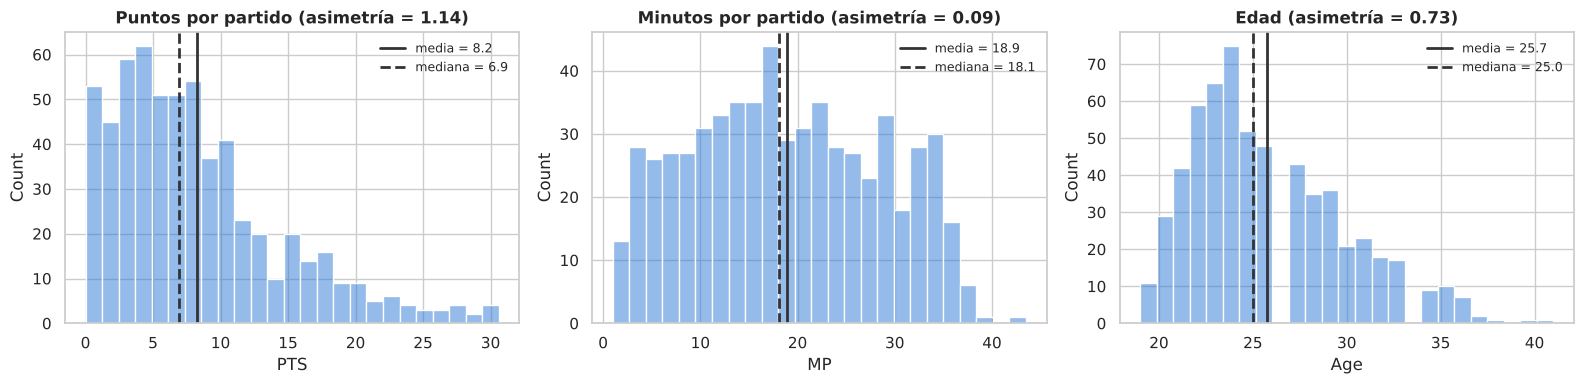

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, v, titulo in [(axes[0], "PTS", "Puntos por partido"), (axes[1], "MP", "Minutos por partido"), (axes[2], "Age", "Edad")]:
    sns.histplot(jug[v], bins=25, color=AZUL, alpha=0.5, ax=ax)
    ax.axvline(jug[v].mean(), color="#333333", lw=2, label=f"media = {jug[v].mean():.1f}")
    ax.axvline(jug[v].median(), color="#333333", ls="--", lw=2, label=f"mediana = {jug[v].median():.1f}")
    ax.set_title(f"{titulo} (asimetría = {jug[v].skew():.2f})"); ax.legend(frameon=False, fontsize=9)
plt.tight_layout(); plt.show()

🤔 Los **puntos** tienen asimetría positiva: muchos jugadores anotan poco y unos pocos anotan muchísimo. ¿Y los **minutos**?
Son casi simétricos. ¿Qué te dice eso de cómo reparten los entrenadores los minutos y de cómo se reparten los puntos?

### Atípicos: las estrellas

In [11]:
q1, q3 = jug["PTS"].quantile(0.25), jug["PTS"].quantile(0.75)
iqr = q3 - q1
ls = q3 + 1.5 * iqr
print(f"Q1 = {q1}, Q3 = {q3}, IQR = {iqr:.1f}  ->  valla superior = {ls:.1f} puntos")
estrellas = jug[jug["PTS"] > ls].sort_values("PTS", ascending=False)
print(f"{len(estrellas)} jugadores anotan más de {ls:.1f} puntos por partido:")
estrellas[["Player", "Posicion", "Tm", "Age", "MP", "PTS"]].head(15)

Q1 = 3.5, Q3 = 11.1, IQR = 7.6  ->  valla superior = 22.5 puntos
25 jugadores anotan más de 22.5 puntos por partido:


,Player,Posicion,Tm,Age,MP,PTS
206,Joel Embiid,Pívot,PHI,27,33.800,30.600
368,LeBron James,Alero,LAL,37,37.200,30.300
15,Giannis Antetokounmpo,Ala-pívot,MIL,27,32.900,29.900
198,Kevin Durant,Ala-pívot,BRK,33,37.200,29.900
178,Luka Don?i?,Base,DAL,22,35.400,28.400
808,Trae Young,Base,ATL,23,34.900,28.400
167,DeMar DeRozan,Ala-pívot,CHI,32,36.100,27.900
356,Kyrie Irving,Base,BRK,29,37.600,27.400
526,Ja Morant,Base,MEM,22,33.100,27.400
391,Nikola Joki?,Pívot,DEN,26,33.500,27.100


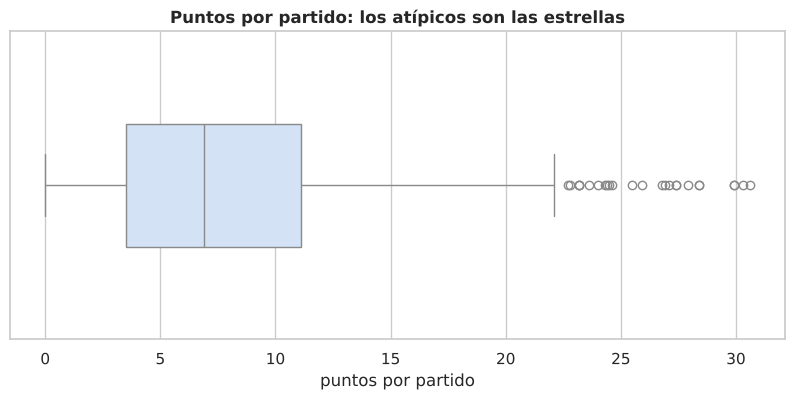

In [12]:
sns.boxplot(x=jug["PTS"], color="#cde2fb", width=0.4)
plt.title("Puntos por partido: los atípicos son las estrellas"); plt.xlabel("puntos por partido")
plt.show()

Aquí el atípico **no es un error**: es exactamente lo que el director deportivo busca. En el negocio del deporte, **el valor está en la cola**.

### 🚀 Retos de la sesión 1
1. ¿Cuántos jugadores jugaron en **3 o más equipos** esa temporada? (pista: cuenta las filas de cada `Rk` en `nba`)
2. Describe los **rebotes** (`TRB`) y las **asistencias** (`AST`): media, mediana, asimetría. ¿Quién es atípico en cada una?
3. ¿Qué jugador jugó **más partidos**? ¿Cuántos jugaron los 82?
4. Tipifica los puntos: ¿cuántas desviaciones típicas por encima de la media está Joel Embiid?

---
✅ **Fin de la sesión 1.**

---
# 🕐 Sesión 2 de 2 · Grupos, porcentajes engañosos, regresión y fichajes
**Objetivos:** comparar posiciones y edades con `groupby`, desconfiar de porcentajes y medias con pocos datos, regresión lineal
de los puntos sobre los minutos y uso de los residuos para encontrar "gangas".
**Apartados:** 5 a 8 · **Duración orientativa:** 2 horas
> 💡 Si abres el notebook en una sesión nueva, ejecuta antes todas las celdas anteriores: menú *Entorno de ejecución → Ejecutar las celdas anteriores* (Ctrl+F8).

## 5. 🏆 El perfil de cada posición

In [13]:
stats_pos = ["PTS", "TRB", "AST", "STL", "BLK", "3PA", "FG%"]
jug.groupby("Posicion")[stats_pos].mean().round(2)

,PTS,TRB,AST,STL,BLK,3PA,FG%
Posicion,,,,,,,
Ala-pívot,8.430,4.220,1.420,0.570,0.500,2.390,0.470
Alero,7.910,3.150,1.420,0.590,0.300,2.930,0.410
Base,9.420,2.660,3.560,0.780,0.240,3.360,0.400
Escolta,7.530,2.340,1.700,0.590,0.200,3.260,0.390
Pívot,8.200,5.520,1.250,0.510,0.720,1.090,0.520


Las variables están en escalas muy distintas (puntos frente a tapones). Para comparar perfiles, **tipificamos** cada variable
y calculamos la media de las puntuaciones z por posición:

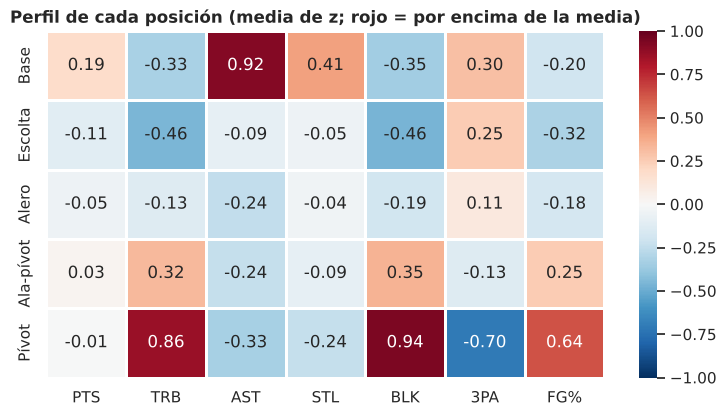

In [14]:
z = (jug[stats_pos] - jug[stats_pos].mean()) / jug[stats_pos].std()
perfil = z.groupby(jug["Posicion"]).mean().loc[["Base", "Escolta", "Alero", "Ala-pívot", "Pívot"]]
plt.figure(figsize=(9, 4.5))
sns.heatmap(perfil, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=2, linecolor="white")
plt.title("Perfil de cada posición (media de z; rojo = por encima de la media)"); plt.ylabel("")
plt.show()

🤔 ¿Qué posición da más **asistencias**? ¿Cuál coge más **rebotes** y pone más **tapones**? ¿Cuál tira más **triples**?
¿Y por qué los pívots tienen el mejor **porcentaje de tiro** (`FG%`)? (pista: ¿desde dónde tiran?)

### ¿Joven o veterano? Puntos por edad

In [15]:
por_edad = jug.groupby("Age")["PTS"].agg(n="size", media="mean", mediana="median")
por_edad.round(1).T

Age,19,20,21,22,23,24,25,26,27,28,29,30,31,32,33,34,35,36,37,38,40,41
n,11.000,29.000,42.000,59.000,65.000,75.000,52.000,48.000,43.000,35.000,36.000,21.000,23.000,18.000,17.000,9.000,10.000,7.000,2.000,1.000,1.000,1.000
media,6.800,8.400,7.600,7.800,8.400,5.800,8.300,8.700,8.500,8.200,9.400,8.300,11.900,10.200,11.800,6.100,7.700,7.600,21.800,4.000,2.000,2.500
mediana,5.800,7.600,7.600,4.700,7.800,4.500,6.500,6.000,5.800,7.400,7.400,8.000,9.400,7.900,11.400,5.900,6.900,6.200,21.800,4.000,2.000,2.500


⚠️ ¡Los jugadores de **37 años** anotan de media 21,8 puntos, el triple que los de 24! ¿Los veteranos son los mejores?
Mira la columna `n`: solo hay **2 jugadores de 37 años**… y uno de ellos es LeBron James.

In [16]:
jug[jug["Age"] >= 37][["Player", "Age", "G", "MP", "PTS"]]

,Player,Age,G,MP,PTS
17,Carmelo Anthony,37,69,26.000,13.300
298,Udonis Haslem,41,13,6.400,2.500
353,Andre Iguodala,38,31,19.500,4.000
368,LeBron James,37,56,37.200,30.300
382,Joe Johnson,40,1,2.000,2.000


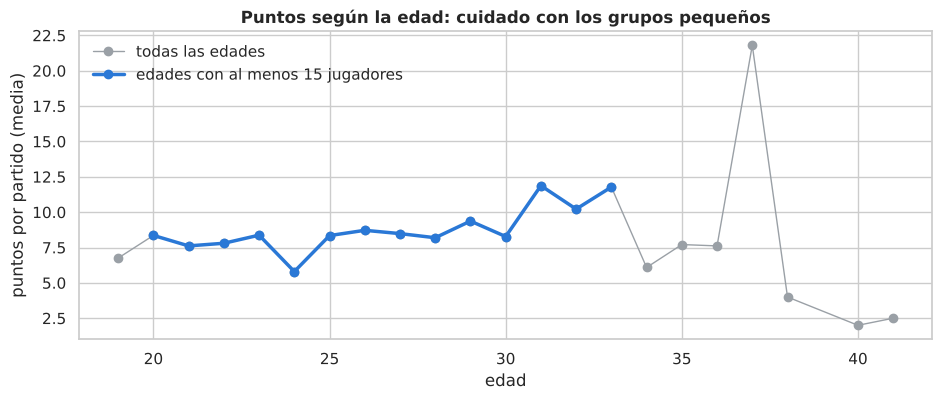

In [17]:
d = por_edad[por_edad["n"] >= 15]
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(por_edad.index, por_edad["media"], marker="o", color="#9aa0a6", lw=1, label="todas las edades")
ax.plot(d.index, d["media"], marker="o", color=AZUL, lw=2.5, label="edades con al menos 15 jugadores")
ax.set_xlabel("edad"); ax.set_ylabel("puntos por partido (media)"); ax.legend(frameon=False)
ax.set_title("Puntos según la edad: cuidado con los grupos pequeños")
plt.show()

## 6. ⚠️ Porcentajes y "por minuto" con pocos datos
El director deportivo pide **el mejor tirador de triples**. Ordenamos por `3P%`:

In [18]:
jug.nlargest(5, "3P%")[["Player", "G", "3PA", "3P%"]]

,Player,G,3PA,3P%
593,Jakob Poeltl,68,0.000,1.000
739,Rayjon Tucker,5,1.000,0.800
357,Wes Iwundu,3,1.700,0.600
110,Vlatko ?an?ar,15,0.800,0.583
255,Anthony Gill,44,0.600,0.538


¡Jakob Poeltl, un pívot, con un **100 %** en triples! Pero su `3PA` (triples intentados por partido) es 0,0: en toda la temporada
intentó apenas uno o dos triples y los metió. Un porcentaje calculado sobre 1 intento no dice nada. Exigimos un mínimo de intentos:

In [19]:
tiradores = jug[(jug["3PA"] >= 3) & (jug["G"] >= 40)]
print(f"Jugadores con al menos 3 triples intentados por partido y 40 partidos: {len(tiradores)}")
tiradores.nlargest(8, "3P%")[["Player", "Tm", "G", "3PA", "3P%"]]

Jugadores con al menos 3 triples intentados por partido y 40 partidos: 191


,Player,Tm,G,3PA,3P%
411,Luke Kennard,LAC,70,6.000,0.449
35,Desmond Bane,MEM,76,6.900,0.436
541,Mike Muscala,OKC,43,3.800,0.429
484,Tyrese Maxey,PHI,75,4.100,0.427
378,Cameron Johnson,PHO,66,5.900,0.425
156,Seth Curry,TOT,64,5.800,0.422
496,Doug McDermott,SAS,51,5.000,0.422
607,Norman Powell,TOT,45,5.600,0.419


Lo mismo pasa con los **puntos por 36 minutos** (una forma habitual de comparar a jugadores que juegan minutos distintos):

In [20]:
jug["PTS_36"] = jug["PTS"] / jug["MP"] * 36
print("Sin filtrar:")
print(jug.nlargest(5, "PTS_36")[["Player", "G", "MP", "PTS", "PTS_36"]].to_string(index=False))
print("\nCon al menos 40 partidos y 20 minutos por partido:")
print(jug[(jug["G"] >= 40) & (jug["MP"] >= 20)].nlargest(5, "PTS_36")[["Player", "G", "MP", "PTS", "PTS_36"]].to_string(index=False))

Sin filtrar:
               Player  G     MP    PTS  PTS_36
          Ahmad Caver  1  1.000  2.000  72.000
          Joe Johnson  1  2.000  2.000  36.000
         Malik Newman  1  8.000  8.000  36.000
Giannis Antetokounmpo 67 32.900 29.900  32.717
          Joel Embiid 68 33.800 30.600  32.592

Con al menos 40 partidos y 20 minutos por partido:
               Player  G     MP    PTS  PTS_36
Giannis Antetokounmpo 67 32.900 29.900  32.717
          Joel Embiid 68 33.800 30.600  32.592
            Ja Morant 57 33.100 27.400  29.801
         LeBron James 56 37.200 30.300  29.323
           Trae Young 76 34.900 28.400  29.295


🎯 Ahmad Caver jugó **un partido de un minuto** y anotó 2 puntos: "72 puntos por 36 minutos". Es la misma trampa que la media
de un país con un solo futbolista o los veteranos de 37 años: **un resumen calculado con muy pocos datos no es fiable**.

## 7. 📈 ¿Cuántos puntos "vale" un minuto? Regresión de los puntos sobre los minutos

In [21]:
x, y = jug["MP"], jug["PTS"]
print(f"Correlación minutos–puntos: r = {x.corr(y):.3f}")

Sxy = ((x - x.mean()) * (y - y.mean())).mean()
Sx2 = ((x - x.mean()) ** 2).mean()
b = Sxy / Sx2
a = y.mean() - b * x.mean()
r2 = 1 - ((y - (a + b * x)) ** 2).sum() / ((y - y.mean()) ** 2).sum()
print(f"Recta: puntos = {a:.2f} + {b:.3f}·minutos      R² = {r2:.3f}")
print(f"Cada minuto más de juego se asocia a {b:.2f} puntos más por partido")

Correlación minutos–puntos: r = 0.884
Recta: puntos = -2.63 + 0.574·minutos      R² = 0.782
Cada minuto más de juego se asocia a 0.57 puntos más por partido


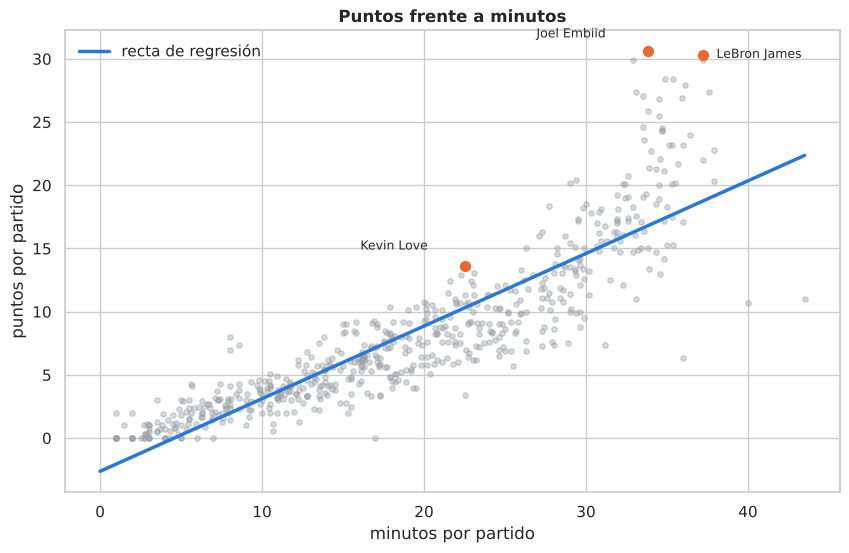

In [22]:
xs = np.linspace(0, x.max(), 100)
plt.figure(figsize=(10, 6))
plt.scatter(x, y, s=15, alpha=0.4, color="#9aa0a6")
plt.plot(xs, a + b * xs, color=AZUL, lw=2.5, label="recta de regresión")
for nombre, desplaz in [("Joel Embiid", (-80, 10)), ("LeBron James", (10, -2)), ("Kevin Love", (-75, 12))]:
    f = jug[jug["Player"] == nombre].iloc[0]
    plt.scatter(f["MP"], f["PTS"], s=50, color=NARANJA, zorder=3)
    plt.annotate(nombre, (f["MP"], f["PTS"]), xytext=desplaz, textcoords="offset points", fontsize=9)
plt.xlabel("minutos por partido"); plt.ylabel("puntos por partido"); plt.legend(frameon=False)
plt.title("Puntos frente a minutos")
plt.show()

🤔 Mira la forma de la nube: ¿es una recta o **se curva hacia arriba** a partir de 30 minutos? Las estrellas juegan más minutos
**y además** anotan más por minuto. (Prueba un modelo potencial en los retos.)

🤔 ¿Tiene sentido la ordenada en el origen negativa? (Un jugador con 0 minutos anotaría puntos negativos…)
La recta solo vale **dentro** del rango de los datos.

🤔 Y ojo con la causalidad: ¿los jugadores anotan más **porque** juegan más minutos, o juegan más minutos **porque** anotan mucho?

### Los residuos: ¿quién anota más de lo que "le toca" por sus minutos?
El residuo $e_i = y_i - \hat y_i$ mide cuántos puntos anota un jugador **por encima o por debajo** de lo esperable para sus minutos.

In [23]:
jug["residuo"] = jug["PTS"] - (a + b * jug["MP"])
fiables = jug[jug["G"] >= 40]
print("Los que más anotan por encima de lo esperado (al menos 40 partidos):")
print(fiables.nlargest(6, "residuo")[["Player", "Tm", "G", "MP", "PTS", "residuo"]].to_string(index=False))

Los que más anotan por encima de lo esperado (al menos 40 partidos):
               Player  Tm  G     MP    PTS  residuo
          Joel Embiid PHI 68 33.800 30.600   13.809
Giannis Antetokounmpo MIL 67 32.900 29.900   13.626
         LeBron James LAL 56 37.200 30.300   11.556
         Kevin Durant BRK 55 37.200 29.900   11.156
            Ja Morant MEM 57 33.100 27.400   11.011
           Trae Young ATL 76 34.900 28.400   10.977


Son las estrellas: no son una sorpresa (y no son baratas). Busquemos **gangas**: jugadores con **pocos minutos** (menos de 25)
que anotan por encima de lo esperado.

In [24]:
gangas = fiables[fiables["MP"] < 25].nlargest(8, "residuo")
gangas[["Player", "Posicion", "Tm", "Age", "G", "MP", "PTS", "residuo"]]

,Player,Posicion,Tm,Age,G,MP,PTS,residuo
461,Kevin Love,Ala-pívot,CLE,33,74,22.500,13.600,3.301
143,DeMarcus Cousins,Pívot,TOT,31,48,15.000,9.000,3.009
754,Moritz Wagner,Pívot,ORL,24,63,15.200,9.000,2.894
497,JaVale McGee,Pívot,PHO,34,74,15.800,9.200,2.749
4,LaMarcus Aldridge,Pívot,BRK,36,47,22.300,12.900,2.715
541,Mike Muscala,Pívot,OKC,30,43,13.800,8.000,2.698
287,Montrezl Harrell,Pívot,TOT,28,71,23.100,13.100,2.456
432,Jonathan Kuminga,Alero,GSW,19,70,16.900,9.300,2.217


## 8. 📝 El informe de fichajes
Con lo que hemos visto, redactad (en 5 líneas) vuestra recomendación al director deportivo. Lo que dicen los datos:
1. **Los puntos están muy concentrados** en unas pocas estrellas (asimetría positiva, atípicos por arriba). Son las de siempre.
2. **Los minutos explican mucho** de los puntos ($R^2 \approx 0{,}78$), pero los **residuos** señalan a jugadores de banquillo que rinden
   más de lo que sus minutos predicen (Kevin Love, DeMarcus Cousins, Moritz Wagner…): candidatos a más minutos o a fichaje barato.
3. **Desconfiad de los porcentajes y medias con pocos datos** (100 % en triples, 72 puntos por 36 minutos, los "veteranos de 37 años").
4. **Cada posición tiene su perfil**: comparad a cada jugador con los de su posición, no con todos.
5. **Lo que no sabemos**: el salario de cada jugador, su defensa, las lesiones… Sin el salario no podemos hablar de verdaderas "gangas".

### 🚀 Retos de la sesión 2
1. Repite la regresión para los **rebotes** frente a los minutos, solo con los pívots. ¿Quién es la "ganga" reboteadora?
2. ¿Qué **equipo** tiene más puntos sumando a todos sus jugadores? (¡cuidado con las filas `TOT`! ¿Qué tabla usarías, `nba` o `jug`?)
3. Calcula el **porcentaje de tiros libres** (`FT%`) medio por posición. ¿Los pívots tiran peor los libres?
4. Busca el mejor **pasador por 36 minutos** (asistencias), con filtros razonables de partidos y minutos.
5. ¿Hay relación entre la **edad** y los puntos? Calcula la correlación y dibuja la nube de puntos.
6. Ajusta un modelo **potencial** $\text{PTS} = a \cdot \text{MP}^b$ (quita antes los jugadores con 0 puntos: ¿por qué?). ¿Sale $b > 1$? ¿Qué significa?

---
🏁 **Fin del notebook.**